In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt



import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


In [2]:
df = pd.read_csv('datasets/Xor_Dataset.csv')

train = df.sample(frac=0.8, random_state=42)
test = df.drop(train.index)

y_train = train['Y'].to_numpy().reshape(-1, 1)
y_test = test['Y'].to_numpy().reshape(-1, 1)

X_train = train.drop(columns=['Y']).to_numpy()
X_test = test.drop(columns=['Y']).to_numpy()

# X_train = np.hstack((np.ones((X_train.shape[0], 1)), X_train))
# X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

In [3]:
epoches = 1000
losses = []
n_features = X_train.shape[1]
n = X_train.shape[0]
lr = 1
lambda_ = 0.01

np.random.seed(4242)

W1 = np.random.randn(n_features, 4)
B1 = np.random.randn(4)

W2 = np.random.randn(4, 1)
B2 = np.random.randn(1)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

for _ in range(epoches):
    Z1 = X_train @ W1 + B1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2 + B2
    A2 = sigmoid(Z2)

    # applying L2 regularization

    l2_penalty = (lambda_ / (2*n)) * (np.sum(W1 ** 2) + np.sum(W2 ** 2))
    l1_penalty = (lambda_ / n) * (np.sum(np.abs(W1)) + np.sum(np.abs(W2)))  

    actual_loss = -np.mean(y_train * np.log(np.clip(A2, 1e-15, 1 - 1e-15)) + (1 - y_train) * np.log(1 - np.clip(A2, 1e-15, 1 - 1e-15)))
    # loss = actual_loss + l2_penalty
    loss = actual_loss + l1_penalty
    losses.append(loss)

    dZ2 = A2 - y_train
    dB2 = np.mean(dZ2, axis=0)
    # dW2 = (A1.T @ dZ2) / n + (lambda_ / n) * W2
    dW2 = (A1.T @ dZ2) / n + (lambda_ / n) * np.sign(W2)  # L1 regularization gradient
    dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)
    dB1 = np.mean(dZ1, axis=0)
    # dW1 = (X_train.T @ dZ1) / n + (lambda_ / n) * W1
    dW1 = (X_train.T @ dZ1) / n + (lambda_ / n) * np.sign(W1)  # L1 regularization gradient

    W1 -= lr * dW1
    B1 -= lr * dB1
    W2 -= lr * dW2
    B2 -= lr * dB2



print("dimensions:")
print(f"X_train: {X_train.shape}, Y_train: {y_train.shape}, W1: {W1.shape}, B1: {B1.shape}, Z1: {Z1.shape}, A1: {A1.shape}, Z2: {Z2.shape}, A2: {A2.shape}, W2: {W2.shape}, B2: {B2.shape}")
print("dZ1:", dZ1.shape, "dW1:", dW1.shape, "dB1:", dB1.shape, "dZ2:", dZ2.shape, "dW2:", dW2.shape, "dB2:", dB2.shape)

Z1 = X_test @ W1 + B1
A1 = sigmoid(Z1)
Z2 = A1 @ W2 + B2
y_pred = sigmoid(Z2)

accuracy = np.mean((y_pred > 0.5) == y_test) * 100
print(f"Test Accuracy: {accuracy:.4f}")
print(W1)
print(B1)
print(W2)
print(B2)


dimensions:
X_train: (8000, 2), Y_train: (8000, 1), W1: (2, 4), B1: (4,), Z1: (8000, 4), A1: (8000, 4), Z2: (8000, 1), A2: (8000, 1), W2: (4, 1), B2: (1,)
dZ1: (8000, 4) dW1: (2, 4) dB1: (4,) dZ2: (8000, 1) dW2: (4, 1) dB2: (1,)
Test Accuracy: 100.0000
[[ 6.49588724 -1.14319783  5.1337882   3.90948982]
 [-4.57943475  1.84635701 -6.6739335   4.29745851]]
[ 1.81309323  1.48557065 -2.35978374 -0.65812117]
[[-9.61580542]
 [-0.90579492]
 [ 9.56914619]
 [ 5.28703471]]
[0.67626563]


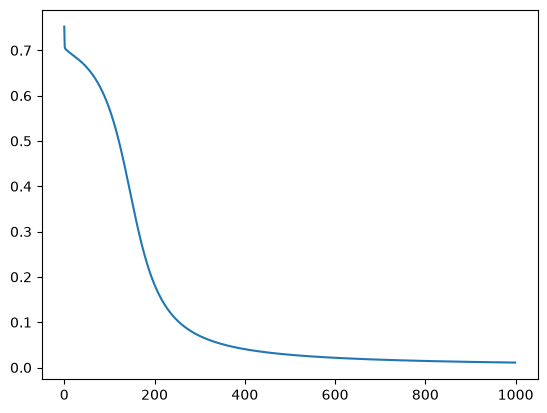

In [4]:
plt.plot(losses)

In [ ]:
# def train_model(lr):

#     tf.keras.backend.clear_session()
#     tf.keras.utils.set_random_seed(42)

#     model = keras.Sequential([
#         layers.Input(shape=(2,)),
#         layers.Dense(2, activation='sigmoid'),
#         layers.Dense(1, activation='sigmoid')
#     ])

#     model.compile(
#         optimizer=keras.optimizers.SGD(learning_rate=lr),
#         loss='mean_squared_error',
#         metrics=['accuracy']
#     )

#     history = model.fit(
#         X, Y,
#         epochs=10000,
#         batch_size=4,
#         verbose=0
#     )

#     return model, history.history['loss']


# # Train using learning rate 0.05
# model1, loss1 = train_model(0.05)

# # Train using learning rate 0.5
# model2, loss2 = train_model(0.5)


# print("Learning Rate = 0.05")
# print("Initial Loss:", loss1[0])
# print("Final Loss:", loss1[-1])

# print("\nLearning Rate = 0.5")
# print("Initial Loss:", loss2[0])
# print("Final Loss:", loss2[-1])


# # Compare loss curves
# plt.figure(figsize=(9, 5))

# plt.plot(loss1, label="Learning Rate = 0.05")
# plt.plot(loss2, label="Learning Rate = 0.5")

# plt.xlabel("Epochs")
# plt.ylabel("MSE Loss")
# plt.title("Learning Rate Comparison")

# plt.legend()
# plt.grid(True)
# plt.show()